In [1]:
from google.colab import files
uploaded = files.upload()

Saving mall.zip to mall.zip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the uploaded CSV dataset
df = pd.read_csv("mall.zip")

# Display the first five rows and check missing values
print(df.head())
print(df.isnull().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [5]:
# Select annual income and spending score for clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Replace missing values with the mean of each column
X = X.fillna(X.mean())

# Scale the features because K-Means uses distance calculations
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display a message after preprocessing
print("Data preprocessing completed")

Data preprocessing completed


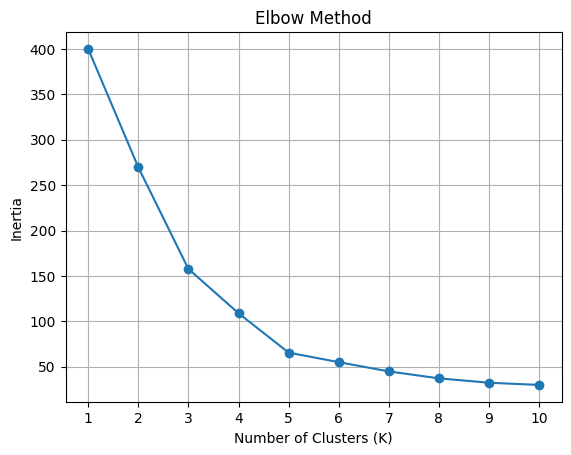

In [6]:
# Create an empty list to store inertia values
inertia = []

# Apply K-Means for K values from 1 to 10
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    # Store the inertia for each K value
    inertia.append(model.inertia_)

# Plot K against inertia to identify the elbow point
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [7]:
# Choose K based on the Elbow graph
k = 5

# Create the K-Means model with five clusters
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

# Assign each data point to its cluster
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Get the cluster centroids and convert them to original units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

# Display the number of points in each cluster
print("Cluster labels:")
print(df['Cluster'].value_counts().sort_index())

# Display the centroid coordinates
print("\nCentroids:")
print(centroids)

Cluster labels:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Centroids:
[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


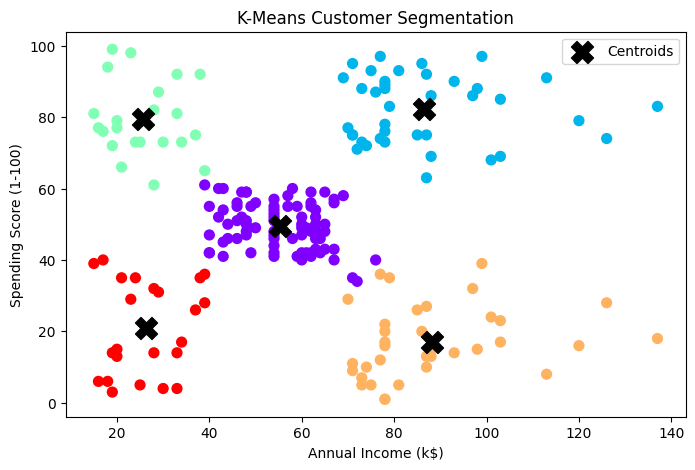

In [8]:
# Create a figure for the cluster scatter plot
plt.figure(figsize=(8, 5))

# Plot customers using different colors for each cluster
plt.scatter(
    X.iloc[:, 0], X.iloc[:, 1],
    c=df['Cluster'], cmap='rainbow', s=50
)

# Mark the centroids with black X symbols
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    marker='X', s=250, color='black', label='Centroids'
)

# Add axis labels, title and legend
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Customer Segmentation")
plt.legend()
plt.show()

In [9]:
# Calculate the average income and spending score for each cluster
print(df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2))

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91
